# OpenSanctions: Iran-Entitäten (Stand 27.10.2026)

## Übersicht
1. Daten laden + Überblick
2. Spalten + Datentypen
3. Fehlende Werte
4. Duplikate
5. Datumsspalten
6. Inhalt verstehen (Entitätstypen, Quellen-Listen)
7. Sanktionierte Einträge filtern
8. Kategorien bilden
9. Sanktionierende Akteure
10. Überschneidung USA und EU
11. Entitätstypen nach Akteur
12. Visualisierung: Sanktionierende Akteure
13. Politische Elite: sanktioniert oder nicht?
14. Sanktionsprogramme
15. Sanktionierte Bereiche (Sektoren)
16. Ämter und Positionen von Personen
17. Finale Tabelle für Filter und Dashboard
18. Limitations
19. Quellen

**Quelle:** OpenSanctions (opensanctions.org), Lizenz CC BY-NC 4.0

## 1. Daten laden + Überblick

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/opensanctions_iran_2026-10-27.csv", low_memory=False)

print(df.shape)          # Zeilen, Spalten
df.head()

(4972, 16)


,id,schema,name,aliases,birth_date,countries,addresses,identifiers,sanctions,phones,emails,program_ids,dataset,first_seen,last_seen,last_change
0,NK-25C73P67uMgzG82QwPnTqg,Company,Sepehr Energy Paya Gostar Jahan,Sepehr Energy;Sepehr Energy Hamta Pars;Sepehr ...,NaN,ir,"No. 41, Second Floor, Shahid Dr. Beheshti St.,...",14012170510;611813;KPP1EKWQQ8Q1,Reciprocal - Active - 2025-02-06;SDGT - Execut...,NaN,NaN,US-TERR,Israel Terrorists Organizations and Unauthoriz...,2025-02-06T16:10:01,2026-10-27T06:27:05,2026-10-06T12:47:00
1,NK-276gB7L8sFEhctkuEpZsus,Company,IRAN OVERSEAS INVESTMENT BANK LIMITED,BANK SADERAT PLC;Bank Saderat PLC;IRAN OVERSEA...,NaN,gb;ie;ir,"120 Moorgate, London EC2M 6TS;5 LOTHBURY LONDO...",01126618;2138008KTNTDICZU8L25;5000387442;50008...,IRAN - Unknown;Reciprocal - Active,442076000133,NaN,US-IRAN,Business Identifier Code (BIC) Reference Data;...,2023-04-20T10:27:20,2026-10-27T06:10:05,2026-09-04T15:37:40
2,NK-27onzGZC8PAWFaVGicUFKy,Person,Mohammad Mahdi Maghfoori,"MAGHFOORI, Mehdi;MAGHFOORI, Mohammad Mahdi;Meh...",1969-12-20,ir,Iran,2982420694;H60608748;PKF3JH76TAS6;QC4RBESY58N6...,;Reciprocal - Active - 2025-11-20;SDGT - Execu...,NaN,NaN,US-TERR,Taiwan Strategic High-Tech Commodities Entity ...,2025-11-20T20:10:01,2026-10-27T06:10:05,2026-08-17T09:46:12
3,NK-28DYyZtuHyHDr3Gk7spEQM,Company,Fars News Agency,Fars News Agency Cultural Institute;خبرگزاری ف...,NaN,ir,"Iran;Number 1, Shahrood Alley, Ferdowsi Square...",10100426798;10581;6000089590,IRAN-HR - Executive Order 13553 (Iran);Iran - ...,NaN,NaN,CA-SEMA;US-IRAN,Canadian Consolidated Autonomous Sanctions Lis...,2023-09-15T14:35:01,2026-10-27T06:43:05,2026-09-02T02:22:05
4,NK-28X5jMopMz2jCXsUDUJczU,Company,Fajr Aviation Composite Industries,Družba Fajr Aviation Composite Industries;FACI...,NaN,ir,"13445-885, Tehran, Mehrabad Airport, IRAN (ISL...",6000095610,";""(UE) 668/2010 du 26/07/2010- (UE Iran prolif...",+982146594579;90214659460 (fax);98 21 4659458(...,faci@fajrind.com;fajr@tco.ac.ir;najarian@fajr....,AU-IRAN;CA-SEMA;EU-IRN;GB-IRAN-NW;SECO-IRAN,Australian Sanctions Consolidated List;Belgian...,2023-04-20T10:12:18,2026-10-27T06:43:05,2026-09-15T10:40:01


## 2. Spalten + Datentypen

In [2]:
df.info()                # Spaltennamen, Typen, Nicht-Null-Werte

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4972 entries, 0 to 4971
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           4972 non-null   object
 1   schema       4972 non-null   object
 2   name         4972 non-null   object
 3   aliases      4002 non-null   object
 4   birth_date   2513 non-null   object
 5   countries    4972 non-null   object
 6   addresses    2018 non-null   object
 7   identifiers  4163 non-null   object
 8   sanctions    2901 non-null   object
 9   phones       266 non-null    object
 10  emails       108 non-null    object
 11  program_ids  2840 non-null   object
 12  dataset      4972 non-null   object
 13  first_seen   4972 non-null   object
 14  last_seen    4972 non-null   object
 15  last_change  4972 non-null   object
dtypes: object(16)
memory usage: 621.6+ KB


## 3. Fehlende Werte

In [3]:
df.isna().sum().sort_values(ascending=False)

emails         4864
phones         4706
addresses      2954
birth_date     2459
program_ids    2132
sanctions      2071
aliases         970
identifiers     809
countries         0
id                0
schema            0
name              0
dataset           0
first_seen        0
last_seen         0
last_change       0
dtype: int64

**Interpretation:** `sanctions` fehlt bei ca. 42 % der Einträge. Das sind vor allem Personen aus Wikidata (PEPs, Politiker), die nicht zwingend sanktioniert sind.

## 4. Duplikate

In [4]:
print("Ganze Zeilen doppelt:", df.duplicated().sum())
print("IDs doppelt:", df["id"].duplicated().sum())
print("Namen doppelt:", df["name"].duplicated().sum())  # gleicher Name ≠ zwingend Fehler

Ganze Zeilen doppelt: 0
IDs doppelt: 0
Namen doppelt: 22


In [5]:
# Doppelte Namen ansehen: verschiedene Entitäten oder echte Dubletten?
df[df["name"].duplicated(keep=False)].sort_values("name")[["id", "schema", "name", "countries"]]

,id,schema,name,countries
4725,icijol-56070367,LegalEntity,AHMAD SARKANDI,gb;ir
1738,NK-ds4dXm3KoPuMk8HvsLBRFT,LegalEntity,AHMAD SARKANDI,gb;hk;ir
2209,NK-m94ucLhgZDo6CuMGctVGgg,Person,Ali Fallahian,ir
2905,Q1399279,Person,Ali Fallahian,ir
1614,NK-bqLVst28vpEnRHqZu2BFaT,Person,Ali Moalemi,ir
4194,Q5933384,Person,Ali Moalemi,ir
417,NK-CMwscxKSVkZuTi9rdd2EUR,Person,Alireza Derakhshan,ae;ir
2036,NK-iiSszZgkW7x3nuSwtAHoUB,Person,Alireza Derakhshan,ae;dm;ir;mc;tr
3589,Q24761097,Person,Davoud Mohammadi,ir
3057,Q16047448,Person,Davoud Mohammadi,ir


## 5. Datumsspalten

In [6]:
date_cols = ["first_seen", "last_seen", "last_change"]
for c in date_cols:
    df[c] = pd.to_datetime(df[c], errors="coerce")

df[date_cols].describe()     # min/max: welcher Zeitraum?

,first_seen,last_seen,last_change
count,4972,4972,4972
mean,2024-07-24 20:57:27.812952320,2026-10-27 00:16:53.214601728,2026-07-16 22:32:46.529364224
min,2019-05-21 00:00:00,2026-09-27 18:18:01,2024-08-08 17:29:03
25%,2023-04-20 10:27:20,2026-10-26 16:54:16,2026-07-13 18:48:46
50%,2024-05-17 15:38:08,2026-10-27 06:10:05,2026-08-21 13:37:01
75%,2026-01-29 18:58:02,2026-10-27 06:10:05,2026-09-15 09:48:57
max,2026-10-18 00:12:05,2026-10-27 06:47:06,2026-10-27 02:14:06


**Hinweis:** `first_seen` ist die erstmalige Erfassung durch OpenSanctions (frühestens 2019), **nicht** das Datum der Sanktion.

## 6. Inhalt verstehen

In [7]:
# Entitätstypen (Company, Person, Vessel ...)
display(df["schema"].value_counts())

# Quellen-Listen (Mehrfachwerte mit ";" getrennt)
display(df["dataset"].str.split(";").explode().value_counts().head(20))

schema
Person          3305
Company         1108
LegalEntity      204
Vessel           201
Organization     154
Name: count, dtype: int64

dataset
US Trade Consolidated Screening List (CSL)            2235
Wikidata                                              2139
US OFAC Specially Designated Nationals (SDN) List     2114
US SAM Procurement Exclusions                         1758
Wikidata Politically Exposed Persons                  1583
PEP position annotations by OpenSanctions             1516
Taiwan Strategic High-Tech Commodities Entity List    1263
US OFAC Press Releases                                1062
PermID Open Data                                       916
Wikidata Persons in Relevant Categories                883
Monaco National Fund Freezing List                     720
French National Asset Freezing System                  720
EU Council Official Journal Sanctioned Entities        713
EU Financial Sanctions Files (FSF)                     712
Belgian Financial Sanctions                            706
Ukraine NSDC State Register of Sanctions               604
UK FCDO Sanctions List                          

## 7. Sanktionierte Einträge filtern

In [8]:
# Nur Einträge mit Sanktionsprogramm
sanc = df[df["program_ids"].notna()].copy()

print("Alle Einträge:        ", len(df))
print("Mit Sanktionsprogramm:", len(sanc))
print("Ohne (z. B. PEPs):    ", len(df) - len(sanc))

Alle Einträge:         4972
Mit Sanktionsprogramm: 2840
Ohne (z. B. PEPs):     2132


## 8. Kategorien bilden

Jeder Eintrag wird einer Kategorie zugeordnet:

- **Sanktioniert**: mindestens ein Sanktionsprogramm (`program_ids`)
- **Nur Exportkontrolle**: keine Sanktion, aber auf einer Exportkontrollliste (z. B. US CSL, Entity List)
- **Nur PEP**: keine Sanktion, aber als politisch exponierte Person erfasst
- **Sonstiges**: andere Quellen (z. B. Firmenregister, Debarment)

Die Reihenfolge ist eine Rangfolge: Wer sanktioniert ist, zählt als „Sanktioniert“, auch wenn er zusätzlich PEP ist.

In [9]:
def kategorie(row):
    ds = row["dataset"]
    if pd.notna(row["program_ids"]):
        return "Sanktioniert"
    if any(x in ds for x in ["Consolidated Screening List", "Entity List", "End User List"]):
        return "Nur Exportkontrolle"
    if "Politically Exposed" in ds or "PEP" in ds:
        return "Nur PEP"
    return "Sonstiges"

df["kategorie"] = df.apply(kategorie, axis=1)

display(df["kategorie"].value_counts())
display(pd.crosstab(df["kategorie"], df["schema"]))

kategorie
Sanktioniert           2840
Nur PEP                1483
Sonstiges               631
Nur Exportkontrolle      18
Name: count, dtype: int64

schema,Company,LegalEntity,Organization,Person,Vessel
kategorie,,,,,
Nur Exportkontrolle,0,18,0,0,0
Nur PEP,0,0,0,1483,0
Sanktioniert,1009,166,148,1316,201
Sonstiges,99,20,6,506,0


In [10]:
# Was steckt in "Sonstiges"?
sonst = df[df["kategorie"] == "Sonstiges"]
display(sonst["dataset"].str.split(";").explode().value_counts().head(15))

dataset
Wikidata                                                  419
Wikidata Persons in Relevant Categories                   341
Graph-based entity tagging                                199
Global Energy Ownership Tracker                            90
Poland Wanted Persons                                      19
US Anti-Kleptocracy and Human Rights Visa Restrictions     19
UK Companies House Disqualified Directors                  17
US FBI Most Wanted                                         15
ICIJ Offshore Leaks Database                               11
US SAM Procurement Exclusions                               7
EBRD Ineligible Entities                                    6
Inter-American Development Bank Sanctions                   6
African Development Bank Debarred Entities                  6
Asian Development Bank Sanctions                            6
WorldBank Debarred Providers                                6
Name: count, dtype: int64

**Interpretation:** „Sonstiges“ besteht fast nur aus Wikidata-Personen, automatisch erkannten Verbindungen zu sanktionierten Akteuren (Graph-based entity tagging) und Firmenregisterdaten. Kleinere Listen wie Fahndungslisten oder Ausschlüsse durch Entwicklungsbanken haben jeweils weniger als 20 Einträge und bekommen keine eigene Kategorie.

## 9. Sanktionierende Akteure

Wer sanktioniert iranische Entitäten? Der Akteur wird aus dem Präfix von `program_ids` gelesen (z. B. `US-IRAN` → US, `EU-IRN` → EU). Eine Entität kann von mehreren Akteuren sanktioniert sein und wird dann bei jedem einmal gezählt.

In [11]:
# Akteur pro Entität nur einmal zählen
akteure = (
    sanc[["id", "program_ids"]]
    .assign(akteur=sanc["program_ids"].str.split(";"))
    .explode("akteur")
    .assign(akteur=lambda x: x["akteur"].str.split("-").str[0])
    .drop_duplicates(["id", "akteur"])
)

akteur_counts = akteure["akteur"].value_counts()
display(akteur_counts)

akteur
US          2242
EU           728
UA           608
GB           577
CA           495
SECO         476
AU           318
UN           130
SA            65
NZ            55
INTERPOL      24
AE            19
SG             1
FR             1
Name: count, dtype: int64

**Interpretation:** Die USA sanktionieren mit Abstand die meisten iranischen Entitäten (2.242 von 2.840, ca. 79 %). Danach folgen EU (728, ca. 26 %), Ukraine (608), Großbritannien (577) und Kanada (495). SECO steht für die Schweiz. INTERPOL ist kein Staat, sondern führt Fahndungsausschreibungen.

## 10. Überschneidung USA und EU

Wie viele sanktionierte Entitäten stehen nur bei den USA, nur bei der EU oder bei beiden auf der Liste?

In [12]:
# Akteure pro Entität als Menge
akteur_set = akteure.groupby("id")["akteur"].apply(set)

us = akteur_set.apply(lambda s: "US" in s)
eu = akteur_set.apply(lambda s: "EU" in s)

ueberschneidung = pd.Series({
    "Nur USA": (us & ~eu).sum(),
    "Nur EU": (~us & eu).sum(),
    "USA und EU": (us & eu).sum(),
    "Weder USA noch EU": (~us & ~eu).sum(),
})
display(ueberschneidung)

Nur USA              1842
Nur EU                328
USA und EU            400
Weder USA noch EU     270
dtype: int64

**Interpretation:** Die meisten sanktionierten Entitäten stehen nur auf US-Listen (1.842). Nur 400 werden von USA und EU gemeinsam sanktioniert, das sind 18 % der US-Fälle, aber 55 % der EU-Fälle. Die EU sanktioniert 328 Entitäten ohne US-Gegenstück, sie folgt den USA also nicht einfach, sondern setzt eigene Schwerpunkte. 270 Entitäten werden weder von den USA noch von der EU sanktioniert (z. B. nur Ukraine, UK, Kanada oder UN).

## 11. Entitätstypen nach Akteur

Welche Arten von Entitäten (Personen, Firmen, Schiffe, Organisationen) sanktionieren die wichtigsten Akteure?

In [13]:
# Entitätstyp zu jedem Akteur hinzufügen
akteure_typ = akteure.merge(sanc[["id", "schema"]], on="id")

top = ["US", "EU", "UA", "GB", "CA", "UN"]
auswahl = akteure_typ[akteure_typ["akteur"].isin(top)]
typ_tab = pd.crosstab(auswahl["akteur"], auswahl["schema"]).loc[top]

display(typ_tab)
display((typ_tab.div(typ_tab.sum(axis=1), axis=0) * 100).round(1))   # Anteile in %

schema,Company,LegalEntity,Organization,Person,Vessel
akteur,,,,,
US,932,113,89,909,199
EU,279,0,48,400,1
UA,150,0,28,422,8
GB,217,0,30,330,0
CA,183,54,21,236,1
UN,72,0,10,48,0


schema,Company,LegalEntity,Organization,Person,Vessel
akteur,,,,,
US,41.6,5.0,4.0,40.5,8.9
EU,38.3,0.0,6.6,54.9,0.1
UA,24.7,0.0,4.6,69.4,1.3
GB,37.6,0.0,5.2,57.2,0.0
CA,37.0,10.9,4.2,47.7,0.2
UN,55.4,0.0,7.7,36.9,0.0


**Interpretation:** Die USA sanktionieren Firmen (42 %) und Personen (41 %) etwa gleich stark und sind fast der einzige Akteur, der Schiffe listet (199 von 201 Schiffen). Das deutet auf einen Schwerpunkt bei Öl- und Seetransporten hin. EU, Ukraine und Großbritannien sanktionieren überwiegend Personen (55 bis 69 %). Die UN listet dagegen vor allem Firmen (55 %). `LegalEntity` ist eine allgemeine Kategorie für nicht näher bestimmte Rechtsträger und kommt nur bei USA und Kanada vor.

## 12. Visualisierung: Sanktionierende Akteure

Balkendiagramm der Anzahl sanktionierter Entitäten je Akteur (Top 8). Gespeichert in `images/` als `opensanctions_akteure.png` (Englisch) und `opensanctions_akteure_de.png` (Deutsch).

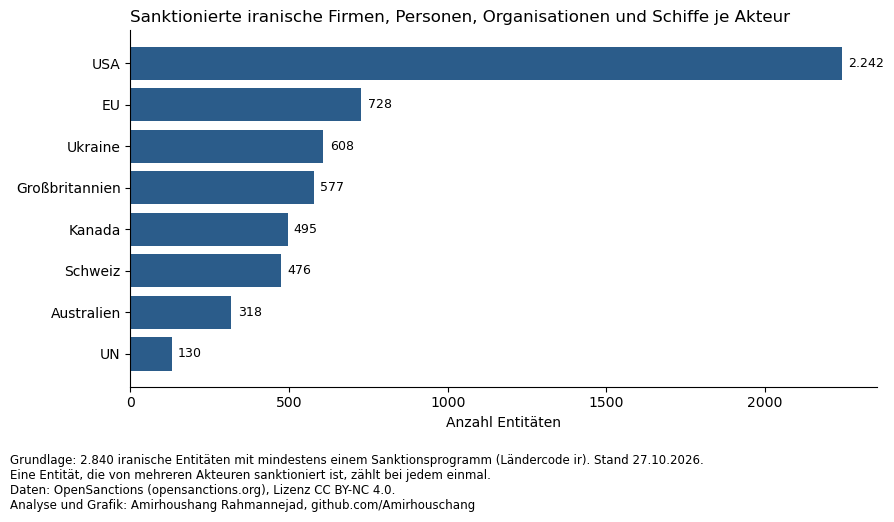

In [14]:
from pathlib import Path

IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(exist_ok=True)

# Lesbare Namen der Akteure je Sprache
AKTEUR_NAMEN = {
    "de": {"US": "USA", "EU": "EU", "UA": "Ukraine", "GB": "Großbritannien", "CA": "Kanada",
           "SECO": "Schweiz", "AU": "Australien", "UN": "UN", "SA": "Saudi-Arabien", "NZ": "Neuseeland"},
    "en": {"US": "United States", "EU": "EU", "UA": "Ukraine", "GB": "United Kingdom", "CA": "Canada",
           "SECO": "Switzerland", "AU": "Australia", "UN": "UN", "SA": "Saudi Arabia", "NZ": "New Zealand"},
}
TXT_AKTEURE = {
    "de": {
        "title": "Sanktionierte iranische Firmen, Personen, Organisationen und Schiffe je Akteur",
        "xlabel": "Anzahl Entitäten",
        "notes": [
            f"Grundlage: {len(sanc):,} iranische Entitäten mit mindestens einem Sanktionsprogramm (Ländercode ir), Stand 27.10.2026.".replace(",", "."),
            "Eine Entität, die von mehreren Akteuren sanktioniert ist, zählt bei jedem einmal.",
            "Daten: OpenSanctions (opensanctions.org), Lizenz CC BY-NC 4.0.",
            "Analyse und Grafik: Amirhoushang Rahmannejad, github.com/Amirhouschang",
        ],
    },
    "en": {
        "title": "Sanctioned Iranian companies, persons, organisations and vessels per actor",
        "xlabel": "Number of entities",
        "notes": [
            f"Based on {len(sanc):,} Iranian entities with at least one sanctions programme (country code ir), as of 27 Oct 2026.",
            "An entity sanctioned by several actors counts once for each.",
            "Data: OpenSanctions (opensanctions.org), licence CC BY-NC 4.0.",
            "Analysis and chart: Amirhoushang Rahmannejad, github.com/Amirhouschang",
        ],
    },
}

top8 = akteur_counts.head(8).sort_values()

for lang in ["de", "en"]:
    t = TXT_AKTEURE[lang]
    labels = [AKTEUR_NAMEN[lang].get(a, a) for a in top8.index]

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.barh(labels, top8.values, color="#2b5c8a")

    # Werte an die Balken schreiben
    for i, v in enumerate(top8.values):
        text = f"{v:,}".replace(",", ".") if lang == "de" else f"{v:,}"
        ax.text(v + 20, i, text, va="center", fontsize=9)

    ax.set_title(t["title"], loc="left")
    ax.set_xlabel(t["xlabel"])
    ax.spines[["top", "right"]].set_visible(False)
    fig.text(0.01, -0.02, "\n".join(t["notes"]), fontsize=8.5, va="top")
    plt.tight_layout()

    # Englisch: <name>.png, Deutsch: <name>_de.png; im Notebook wird die deutsche Fassung angezeigt
    filename = "opensanctions_akteure.png" if lang == "en" else "opensanctions_akteure_de.png"
    fig.savefig(IMAGES_DIR / filename, dpi=150, bbox_inches="tight")
    if lang == "de":
        plt.show()
    else:
        plt.close(fig)


## 13. Politische Elite: sanktioniert oder nicht?

Wie viele der als PEP erfassten iranischen Personen (Politiker, Amtsträger) sind sanktioniert?

In [15]:
# PEP unabhängig von Sanktion markieren
df["ist_pep"] = df["dataset"].str.contains("Politically Exposed|PEP", regex=True)

pep = df[df["ist_pep"] & (df["schema"] == "Person")]

pep_status = pep["kategorie"].replace({"Nur PEP": "Nicht sanktioniert"}).value_counts()
display(pep_status)
print(f"Anteil sanktioniert: {(pep['kategorie'] == 'Sanktioniert').mean() * 100:.1f} %")

kategorie
Nicht sanktioniert    1483
Sanktioniert           113
Name: count, dtype: int64

Anteil sanktioniert: 7.1 %


**Interpretation:** Von 1.596 iranischen PEPs sind nur 113 sanktioniert (ca. 7 %). Sanktionen treffen also nicht die politische Elite insgesamt, sondern gezielt einzelne Personen. Einschränkung: Der Anteil bezieht sich auf die erfassten PEPs einschließlich ehemaliger Amtsträger; für die aktuelle politische Elite lässt er sich daraus nicht bestimmen.

## 14. Sanktionsprogramme

Welche konkreten Programme stehen hinter den Sanktionen? Die Codes zeigen das Thema, z. B. `US-IRAN` (Iran allgemein), `US-TERR` (Terrorismus), `EU-IRN` (EU-Iran-Programm).

In [16]:
programme = (
    sanc[["id", "program_ids"]]
    .assign(programm=sanc["program_ids"].str.split(";"))
    .explode("programm")
    .drop_duplicates(["id", "programm"])
)

display(programme["programm"].value_counts().head(15))

programm
US-IRAN          1565
EU-IRN            673
UA-SA1644         600
CA-SEMA           489
SECO-IRAN         437
GB-IRAN-NW        281
GB-IRAN           255
AU-IRAN           230
US-NON-PROLIF     225
US-TERR           216
UN-SC1737         119
US-BIS-EL         115
SA-UNSC1373        65
NZ-RSA2022         54
AU-HUMAN           48
Name: count, dtype: int64

**Interpretation:** Die meisten Sanktionen laufen über länderspezifische Iran-Programme (US-IRAN, EU-IRN, SECO-IRAN, GB-IRAN, AU-IRAN). Dazu kommen thematische Programme: Nichtverbreitung von Massenvernichtungswaffen (US-NON-PROLIF, GB-IRAN-NW, UN-SC1737 zum iranischen Atomprogramm) und Terrorismus (US-TERR, SA-UNSC1373). NZ-RSA2022 gehört zu Neuseelands Russland-Sanktionen und zeigt, dass iranische Akteure auch wegen ihrer Unterstützung Russlands gelistet werden. US-BIS-EL ist streng genommen eine Exportkontrollliste (Entity List), wird von OpenSanctions aber als Programm geführt.

## 15. Sanktionierte Bereiche (Sektoren)

OpenSanctions enthält keine Branchenangabe. Der Sektor wird daher über englische und persische Schlüsselwörter bestimmt, in drei Stufen:

1. Schiffe (`Vessel`) werden direkt der Schifffahrt zugeordnet.
2. Eindeutige Typwörter im Namen haben Vorrang (z. B. Bank, University, Insurance, Ministry, Airlines). Wer „Bank“ im Namen trägt, ist eine Bank.
3. Danach werden Themen-Schlüsselwörter in Name und Aliasen gesucht.
4. Gibt es dort keinen Treffer, wird der Begründungstext der Sanktionslisten (`sanctions`) durchsucht.

Die Spalte `zuordnung_ueber` zeigt, über welche Stufe die Zuordnung erfolgt ist. Die Reihenfolge der Sektoren ist eine Rangfolge: Der erste Treffer zählt. Personen werden nicht zugeordnet.

In [17]:
# Stufe 1: eindeutige Typwörter, nur im Namen (haben Vorrang)
typwoerter = {
    "Universitäten":                  r"universit|daneshgah",
    "IRGC / Quds / Basij":            r"revolutionary guard|\birgc\b|quds force|\bbasij",
    "Milizen / bewaffnete Gruppen":   r"brigade|hezbollah|hizballah|militia|\bkataib",
    "Nuklear":                        r"nuclear|atomic|uranium",
    "Bank / Finanzen":                r"\bbank\b|\bexchange\b|brokerage|leasing|\bsarafi",
    "Versicherung":                   r"insurance|\bbimeh",
    "Medien":                         r"news agency|\bnews\b|broadcasting|\btv\b|\bpress\b|radio",
    "Ministerien / Behörden":         r"ministry|prison|police|judiciary|\bcourt\b",
    "Stiftungen (Bonyad)":            r"foundation|\bbonyad",
    "Luftfahrt":                      r"airline|airways|aviation|\bair\b|airport",
    "Metall / Bergbau":               r"steel|fulad|foolad|mining|\bmines?\b",
    "Energie (Öl, Gas, Strom)":       r"refin|petrochemical|\boil\b|\bgas\b|electricity",
    "Schifffahrt / Häfen":            r"shipping|tanker|maritime|\bport\b",
    "Fahrzeuge / Maschinenbau":       r"khodro|automotive",
}

# Stufe 2 und 3: Themen-Schlüsselwörter
# Rangfolge: erster Treffer zählt (englische und persische Schlüsselwörter)
sektoren = {
    "Universitäten":                  r"universit|daneshgah",
    "IRGC / Quds / Basij":            r"revolutionary guard|\birgc\b|quds force|\bbasij|pasdaran",
    "Milizen / bewaffnete Gruppen":   r"brigade|hezbollah|hizballah|militia|\bkataib|harakat|\bhamas\b|houthi|ansarallah",
    "Medien":                         r"\bnews\b|media|broadcast|\btv\b|\birib\b|\bpress\b|radio|kayhan",
    "Stiftungen (Bonyad)":            r"foundation|bonyad|\bsetad\b|endowment|charity|astan quds",
    "Nuklear":                        r"nuclear|atomic|uranium|centrifuge|radiation|heavy water|\baeoi\b",
    "Rüstung / Militär":              r"defen[cs]e|military|missile|ammunition|weapon|armed forces|\barmy\b|armée|artesh|modafl|aerospace|\bdrone|\buav\b|\baio\b|\bdio\b|explosive|rocket",
    "Bank / Finanzen":                r"bank|credit|financ|exchange|investment|leasing|capital|\bfund\b|holding|crypto|sarmay|etebar|sarafi|payment",
    "Versicherung":                   r"insurance|\bbimeh",
    "Energie (Öl, Gas, Strom)":       r"\boil\b|petro|\bgas\b|refin|\bnaft|energy|fuel|drilling|electricity|power generation|methanol|\bnirou|\bniroo|\bbargh",
    "Schifffahrt / Häfen":            r"shipping|marine|maritime|tanker|navigation|\bship|\bport\b|\bsea\b|darya|kashtirani|vessel|ocean|offshore|merine|\bbahr\b",
    "Luftfahrt":                      r"aviation|aircraft|airline|airways|\bair\b|helicopter|havapeyma|airport",
    "Bahn / Transport / Logistik":    r"\brail|train|transport|logistic|tarabar|rah ahan|forwarding|freight",
    "Metall / Bergbau":               r"steel|mining|\bmine|metal|copper|alumin|iron|fulad|foolad|\bmadan|\bcoal",
    "Elektronik / IT / Telekom":      r"electronic|electro|communication|telecom|cyber|software|technolog|comput|informatic|pardazesh|rayaneh|optic|laser|\bdata\b|network|electric|persistent threat|\bapt\d",
    "Chemie / Pharma":                r"chemical|pharma|medical|polymer|composite|shimi|darou|daru|fertili[sz]er|\burea\b",
    "Bau / Ingenieurwesen":           r"construction|engineering|khatam|cement|sazeh|omran|sakhteman|maskan|\bbuild|engineer",
    "Fahrzeuge / Maschinenbau":       r"khodro|automotive|motor|zamyad|machine|heavy equipment|vehicle",
    "Textil / Konsumgüter":           r"textile|selkbaf|carpet|\bhejab\b",
    "Landwirtschaft / Lebensmittel":  r"\bagri|\bagro|\bfood|\bfarm\b|\bfish|tractor|keshavarzi",
    "Ministerien / Behörden":         r"ministry|government|council|judiciary|court|prison|police|intelligence|organization of|amniyat",
    "Forschungsinstitute":            r"research|institute|academy",
    "Handel / Import-Export":         r"trading|trade|commerce|commercial|import|export|tejarat|tejari|bazargani|\bgeneral trading",
}

def finde_sektor(text, liste):
    for name, muster in liste.items():
        if re.search(muster, text):
            return name
    return None

def sektor(row):
    # 1. Schiffe direkt zuordnen
    if row["schema"] == "Vessel":
        return pd.Series(["Schifffahrt / Häfen", "Typ (Schiff)"])
    # 2. Eindeutiges Typwort im Namen (z. B. Bank, University, Insurance)
    s = finde_sektor(row["name"].lower(), typwoerter)
    if s:
        return pd.Series([s, "Typwort im Namen"])
    # 3. Themen-Schlüsselwörter in Name und Aliasen
    name_text = f"{row['name']} {row['aliases'] if pd.notna(row['aliases']) else ''}".lower()
    s = finde_sektor(name_text, sektoren)
    if s:
        return pd.Series([s, "Name/Alias"])
    # 4. Falls kein Treffer: Begründungstext der Sanktionslisten
    if pd.notna(row["sanctions"]):
        s = finde_sektor(row["sanctions"].lower(), sektoren)
        if s:
            return pd.Series([s, "Sanktionsbegründung"])
    return pd.Series(["Nicht zuordenbar", "-"])

# Nur Firmen, Organisationen, Schiffe (keine Personen)
nicht_person = sanc[sanc["schema"] != "Person"].copy()
nicht_person[["sektor", "zuordnung_ueber"]] = nicht_person.apply(sektor, axis=1)

display(nicht_person["sektor"].value_counts())
display(nicht_person["zuordnung_ueber"].value_counts())


sektor
Schifffahrt / Häfen              278
Nicht zuordenbar                 249
Energie (Öl, Gas, Strom)         162
Bank / Finanzen                  139
Elektronik / IT / Telekom         95
Nuklear                           82
Bau / Ingenieurwesen              72
Rüstung / Militär                 69
Luftfahrt                         57
Handel / Import-Export            55
Metall / Bergbau                  54
IRGC / Quds / Basij               40
Ministerien / Behörden            33
Forschungsinstitute               23
Bahn / Transport / Logistik       22
Chemie / Pharma                   18
Stiftungen (Bonyad)               17
Medien                            15
Fahrzeuge / Maschinenbau          15
Universitäten                     12
Milizen / bewaffnete Gruppen       8
Versicherung                       5
Landwirtschaft / Lebensmittel      2
Textil / Konsumgüter               2
Name: count, dtype: int64

zuordnung_ueber
Name/Alias             535
Typwort im Namen       418
-                      249
Typ (Schiff)           201
Sanktionsbegründung    121
Name: count, dtype: int64

In [18]:
# Beispiele je Sektor ansehen
for s in nicht_person["sektor"].value_counts().index:
    print(f"\n{s}:")
    print(nicht_person[nicht_person["sektor"] == s]["name"].head(5).tolist())


Schifffahrt / Häfen:
['ASTARA', 'GOLBON', 'BANEH', 'IRAN CHARAK', 'fifteenth ocean gmbh & co. kg']

Nicht zuordenbar:
['PARS MCS CO.', 'Azar Pad Qeshm', 'Bahman Diesel Co.', 'Naghsh Simorgh Sahand LLC', 'MARUN SEPEHR OFOGH COMPANY']

Energie (Öl, Gas, Strom):
['Sepehr Energy Paya Gostar Jahan', 'MARJAN METHANOL COMPANY', 'Iranian Investment Petrochemical Group Company', 'Aghajari Oil & Gas Production Company', 'GHADIR SOLAR ELECTRICITY AND ENERGY']

Bank / Finanzen:
['IRAN OVERSEAS INVESTMENT BANK LIMITED', 'Eghtesad Novin Bank', 'Ansar Bank Brokerage Company', 'Cyrus Offshore Bank', 'Ansar Exchange']

Elektronik / IT / Telekom:
['AMN PARDAZESH KHARAZMI', 'General Electronic', 'Tadbir Sanaat Sharif Technology Development Center', 'AJILY SOFTWARE PROCUREMENT GROUP', 'Fanavari Electro Moj Mobin Company']

Nuklear:
['Radiation Applications Development Company', 'Ertebat Gostar Novin', 'Tosse Silooha', 'Schiller Novin', 'Fan Pardazan']

Bau / Ingenieurwesen:
['Sazeh Morakab Co. Ltd', 'Beh

**Interpretation:** Von 1.524 sanktionierten Firmen, Organisationen und Schiffen lassen sich 1.275 (84 %) einem Sektor zuordnen: 418 über ein eindeutiges Typwort im Namen, 535 über Schlüsselwörter in Name oder Alias, 201 als Schiffe und 121 über die Sanktionsbegründung. Am stärksten betroffen ist die Schifffahrt (278, davon 201 Schiffe), gefolgt von Energie (162, vor allem Öl und Petrochemie) und Banken/Finanzen (139, darunter viele Wechselstuben). Militärische Bereiche sind zusammen ähnlich groß: Nuklear (82), Rüstung (69) und IRGC (40) ergeben 191 Einträge. Dazu kommen 12 Universitäten, darunter militärnahe wie Malek Ashtar und Imam Hossein, sowie Ministerien, Gerichte und Gefängnisse (33). Viele Rüstungsfirmen mit neutralen Namen („Shahid … Industries“) werden erst über die Sanktionsbegründung erkannt. Das Muster zeigt: Sanktionen zielen auf Exporteinnahmen (Öl, Transport), Finanzkanäle und das Militär- und Atomprogramm. 249 Einträge (16 %) bleiben nicht zuordenbar.

## 16. Ämter und Positionen von Personen

Die Ämter stammen aus der Datei `targets.nested.json` von OpenSanctions und wurden mit dem Skript `03_load_opensanctions_positions.py` extrahiert. Es gibt zwei Arten:

- **Occupancy:** Amt mit Zeitraum und Status (`current` = aktuell, `ended` = beendet), vor allem bei PEPs
- **Freitext:** Positionsangabe aus den Sanktionslisten, z. B. „Commander of …“

Ziel: Für sanktionierte und nicht sanktionierte Personen sichtbar machen, welche Ämter sie innehaben oder innehatten.

In [19]:
# Ämter aus Skript 03 laden
pos = pd.read_csv("data/opensanctions_iran_positionen_2026-10-27.csv", dtype=str)
pos = pos.dropna(subset=["position"]).drop_duplicates(["id", "position", "start", "ende"])

# Kategorie (sanktioniert, nur PEP ...) dazuholen
pos = pos.merge(df[["id", "name", "kategorie"]], on="id", how="left")

print("Ämter gesamt:", len(pos))
print("Personen mit Amt:", pos["id"].nunique())
display(pos.groupby("kategorie")["id"].nunique().rename("personen_mit_amt"))
display(pos["status"].fillna("unbekannt").value_counts())


Ämter gesamt: 6764
Personen mit Amt: 2162


kategorie
Nur PEP         1483
Sanktioniert     540
Sonstiges        139
Name: personen_mit_amt, dtype: int64

status
unbekannt    5474
ended        1240
current        50
Name: count, dtype: int64

Die Ämter liegen in vielen Sprachen vor (Englisch, Französisch, Ukrainisch, Japanisch, Persisch). Sie werden daher über Schlüsselwörter zu **Amtsgruppen** zusammengefasst. Die Reihenfolge ist eine Rangfolge: Der erste Treffer zählt.

In [20]:
# Ämter zu Gruppen zusammenfassen (Englisch, Französisch, Persisch gemischt)
amtsgruppen = {
    "Historische Herrscher":         r"satrap|ruler of|\bking\b|\bshah\b|\bemperor|\bsultan",
    "Ausländische Parlamente":       r"bundestag|riksdag|european parliament|house of commons|congress|tweede kamer|storting|folketing|national assembly|house of lords|senate|chamber of representatives|assembly of quebec|council of representatives of iraq",
    "Revolutionsführer / Büro":      r"supreme leader|leader's office|office of the leader|rahbar|leadership council|ولی فقیه|representative of the leader",
    "Bewaffnete Gruppen (Ausland)":  r"hamas|hezbollah|hizballah|islamic jihad|politburo|houthi",
    "Expertenrat":                   r"assembly of experts",
    "Parlament (Majles)":            r"consultative assembly|majles|majlis|parliament|parlement|député|deputy of",
    "Wächterrat / Schlichtungsrat":  r"guardian council|expediency",
    "Justiz":                        r"justice|judge|judiciary|judicial|prosecutor|attorney|court|juge|procureur|tribunal|prison|judiciaire|суд|ministère public",
    "Geheimdienst / Sicherheit":     r"intelligence|security council|police|renseignement|sécurité|escadron|squad|arrest|law enforcement|forces de l.ordre|cyber|поліц",
    "Militär / IRGC":                r"brigad|major.general|lieutenant.general|^general$|^général$|général de division|general staff|генерал|бригад|armed forces|officer|modafl|defense|defence|missile|aerospace|аерокосміч|кодс|\baio\b|aviation industr|colonel|commander|commandant|admiral|amiral|irgc|guard corps|gardiens|army|armée|basij|quds|navy|air force|military|militaire",
    "Staatsmedien":                  r"\birib\b|broadcasting|radio|télévision|television|media|journalist|reporter",
    "Atomenergie":                   r"atomic|atomique|nuclear|nucléaire|aeoi|natanz|enrichment|heavy water|centrifug|santrifüj|原子力|ニュークリア|重水|ядерн|атомн",
    "Regierung / Minister":          r"minister|ministre|president|président|cabinet|government",
    "Diplomatie":                    r"ambassador|ambassadeur|embassy|consul|envoy|permanent representative|foreign affairs|embajada|ambassade|посол",
    "Provinz / Kommunal":            r"governor|gouverneur|mayor|maire|city council|province",
    "Religiöse Ämter":               r"ayatollah|friday prayer|imam|cleric|seminary|hojatoleslam",
    "Wirtschaft / Unternehmen":      r"\bceo\b|chief executive|chairman|director|directeur|managing|manager|company|bank|банк|board|conseil d.administration|ingénieur|engineer",
}

def amtsgruppe(text):
    t = str(text).lower()
    for gruppe, muster in amtsgruppen.items():
        if re.search(muster, t):
            return gruppe
    return "Sonstige"

pos["amtsgruppe"] = pos["position"].apply(amtsgruppe)

# Personen je Amtsgruppe und Kategorie (jede Person pro Gruppe nur einmal)
gruppen_tab = pd.crosstab(
    pos.drop_duplicates(["id", "amtsgruppe"])["amtsgruppe"],
    pos.drop_duplicates(["id", "amtsgruppe"])["kategorie"],
)
gruppen_tab = gruppen_tab.sort_values("Sanktioniert", ascending=False)
display(gruppen_tab)

# Anteil sanktioniert je Amtsgruppe
anteil = (gruppen_tab["Sanktioniert"] / gruppen_tab.sum(axis=1) * 100).round(1)
display(anteil.sort_values(ascending=False).rename("anteil_sanktioniert_%"))


kategorie,Nur PEP,Sanktioniert,Sonstiges
amtsgruppe,,,
Militär / IRGC,14,226,3
Sonstige,23,120,16
Geheimdienst / Sicherheit,3,116,1
Justiz,8,100,1
Wirtschaft / Unternehmen,7,89,1
Regierung / Minister,172,66,35
Parlament (Majles),997,45,39
Atomenergie,1,29,0
Provinz / Kommunal,149,28,47


amtsgruppe
Bewaffnete Gruppen (Ausland)    100.0
Geheimdienst / Sicherheit        96.7
Atomenergie                      96.7
Militär / IRGC                   93.0
Wirtschaft / Unternehmen         91.8
Justiz                           91.7
Staatsmedien                     90.0
Sonstige                         75.5
Revolutionsführer / Büro         63.2
Wächterrat / Schlichtungsrat     52.6
Religiöse Ämter                  25.0
Regierung / Minister             24.2
Provinz / Kommunal               12.5
Diplomatie                        7.5
Expertenrat                       7.4
Ausländische Parlamente           7.1
Parlament (Majles)                4.2
Historische Herrscher             0.0
Name: anteil_sanktioniert_%, dtype: float64

In [21]:
# Häufigste Ämter: sanktionierte Personen
display(pos[pos["kategorie"] == "Sanktioniert"]["position"].value_counts().head(20))

# Häufigste Ämter: nicht sanktionierte PEPs
display(pos[pos["kategorie"] == "Nur PEP"]["position"].value_counts().head(20))


position
Général de brigade                                             40
Member of the Islamic Consultative Assembly                    35
Brigadier General                                              33
Brigadier-General                                              20
Colonel                                                        14
Member of the Expediency Discernment Council                   13
Member of the Assembly of Experts                              10
General                                                         8
Général                                                         7
Minister of Defense and Armed Forces Logistics                  6
Vice President & Head, Atomic Energy Organization of Iran       6
Minister of Petroleum of Iran                                   6
Commander-in-Chief of the Islamic Revolutionary Guard Corps     6
Secretary of the Supreme National Security Council              6
Minister of Intelligence                                        5
C

position
Member of the Islamic Consultative Assembly                1056
Member of the Islamic Consultative Assembly (2016-2020)     204
Member of the Islamic Consultative Assembly (2012-2016)     172
Member of the Assembly of Experts                           160
Member of the Islamic Consultative Assembly (2004-2008)     130
Member of the Islamic Consultative Assembly (2008-2012)     129
Member of the Islamic Consultative Assembly (2024-)          85
Member of the Assembly of Experts (2024-)                    45
Member of the Islamic Consultative Assembly (1996-2000)      40
Vice President of Iran                                       34
Member of the Majles                                         31
Member of the Assembly of Experts (2016-2024)                29
Majles (member, 2012-2016)                                   25
Member of the Islamic Consultative Assembly (1980-1984)      19
Member of the Assembly of Experts (2007-2024)                18
Minister of Education          

**Interpretation:** 2.162 Personen haben mindestens eine Amtsangabe (540 sanktioniert, 1.483 nur PEP, 139 sonstige). Der Status ist meist unbekannt, nur 50 Ämter sind als aktuell markiert. Die Ämter der beiden Gruppen unterscheiden sich deutlich. Sanktionierte Personen kommen vor allem aus Militär und IRGC (226), Geheimdienst und Sicherheitskräften (116), Justiz (100) und Wirtschaft (89). Nicht sanktionierte PEPs sind vor allem Parlamentsabgeordnete (997), Regierungsmitglieder (172), Provinzpolitiker (149), Mitglieder des Expertenrats (147) und Diplomaten (144). Beim Anteil sanktioniert liegen Sicherheitsapparat, Atomprogramm, Militär, Wirtschaft, Justiz und Staatsmedien bei 90 bis 97 %, Parlament nur bei 4 %, Expertenrat bei 7 % und Diplomatie bei 8 %. Sanktionen treffen also gezielt den Repressions-, Sicherheits- und Rüstungsapparat und kaum die gewählten oder repräsentativen Institutionen.

In [22]:
# Ämter je Person zusammenfassen (für die finale Tabelle)
def verbinden(x):
    return "; ".join(sorted(set(x.dropna())))

aemter = pos.groupby("id")["position"].apply(verbinden).rename("aemter")
aemter_aktuell = (
    pos[pos["status"] == "current"]
    .groupby("id")["position"].apply(verbinden)
    .rename("aemter_aktuell")
)
gruppen_je_person = pos.groupby("id")["amtsgruppe"].apply(verbinden).rename("amtsgruppen")

aemter_je_person = pd.concat([aemter, aemter_aktuell, gruppen_je_person], axis=1).fillna("")
aemter_je_person.head()


,aemter,aemter_aktuell,amtsgruppen
id,,,
NK-2QdZaCz27fa4J9EXubJsz2,Directeur de prisons dans la province de l’Aze...,,Justiz
NK-3cFKXVLZNMLVgaQpxfwikR,Ancien procureur de Sirjan; Chef du départemen...,,Justiz
NK-3i2AnmAEca5PHmsoR8DpYv,Commandant adjoint chargé des affaires politiq...,,Militär / IRGC
NK-47US9RAkrjCr9J4y9dcPJm,IRGC Commander of Lorestan Province,,Militär / IRGC
NK-4S8zv22NhcPQZP6PTa2dDV,Brigadier General in Iran’s Army and Chairman ...,,Militär / IRGC


## 17. Finale Tabelle für Filter und Dashboard

Alle Ergebnisse werden in einer Tabelle zusammengeführt. Jede Zeile ist eine Entität, jede Spalte ein Filter: Typ, Kategorie, Sektor, sanktionierende Akteure (als Liste und als Ja/Nein-Spalten), PEP, Programme. Geburtsdaten, Adressen, Telefonnummern, E-Mails und Ausweisnummern (`identifiers`) werden nicht übernommen.

Die Ämter aus Abschnitt 16 kommen als Spalten `amtsgruppen`, `aemter` (alle) und `aemter_aktuell` (Status aktuell) dazu.

Gespeichert werden zwei Dateien:
- `opensanctions_iran_dashboard_2026-10-27.csv`: eine Zeile pro Entität
- `opensanctions_iran_akteure_2026-10-27.csv`: eine Zeile pro Entität und Akteur (für Filter nach Akteur im Dashboard)

In [23]:
# Lesbare Namen für Akteure und Entitätstypen
akteur_namen = {
    "US": "USA", "EU": "EU", "UA": "Ukraine", "GB": "Großbritannien", "CA": "Kanada",
    "SECO": "Schweiz", "AU": "Australien", "UN": "UN", "SA": "Saudi-Arabien",
    "NZ": "Neuseeland", "INTERPOL": "INTERPOL", "AE": "VAE", "SG": "Singapur", "FR": "Frankreich",
}
typ_namen = {
    "Person": "Person", "Company": "Firma", "Organization": "Organisation",
    "LegalEntity": "Rechtsträger", "Vessel": "Schiff",
}

final = df.copy()

# Sektor für alle Nicht-Personen bestimmen (auch nicht sanktionierte)
ist_person = final["schema"] == "Person"
final[["sektor", "zuordnung_ueber"]] = None
final.loc[~ist_person, ["sektor", "zuordnung_ueber"]] = final[~ist_person].apply(sektor, axis=1).values
final.loc[ist_person, "sektor"] = "Person (kein Sektor)"
final.loc[ist_person, "zuordnung_ueber"] = "-"

# Akteure je Entität als lesbare Liste
akteur_liste = (
    akteure.assign(akteur=akteure["akteur"].map(akteur_namen).fillna(akteure["akteur"]))
    .groupby("id")["akteur"]
    .apply(lambda x: "; ".join(sorted(x)))
)
final["akteure"] = final["id"].map(akteur_liste).fillna("")
final["anzahl_akteure"] = final["akteure"].apply(lambda x: len(x.split("; ")) if x else 0)

# Ja/Nein-Spalten für die wichtigsten Akteure (einfaches Filtern)
for code, spalte in [("USA", "usa"), ("EU", "eu"), ("Großbritannien", "uk"), ("UN", "un"),
                     ("Ukraine", "ukraine"), ("Kanada", "kanada"), ("Schweiz", "schweiz"),
                     ("Australien", "australien")]:
    final[f"sanktioniert_{spalte}"] = final["akteure"].str.contains(code, regex=False)

# Spalten umbenennen und auswählen (ohne Kontaktdaten und Ausweisnummern)
final = final.rename(columns={
    "program_ids": "programme",
    "countries": "laender",
    "dataset": "quellen_listen",
    "sanctions": "sanktionsbegruendung",
    "first_seen": "erstmals_erfasst",
    "last_change": "letzte_aenderung",
})
final["typ"] = final["schema"].map(typ_namen)
final["erstmals_erfasst"] = final["erstmals_erfasst"].dt.date
final["letzte_aenderung"] = final["letzte_aenderung"].dt.date

spalten = [
    "id", "name", "aliases", "typ", "kategorie", "sektor", "zuordnung_ueber",
    "akteure", "anzahl_akteure",
    "sanktioniert_usa", "sanktioniert_eu", "sanktioniert_uk", "sanktioniert_un",
    "sanktioniert_ukraine", "sanktioniert_kanada", "sanktioniert_schweiz", "sanktioniert_australien",
    "ist_pep", "programme", "laender", "quellen_listen", "sanktionsbegruendung",
    "erstmals_erfasst", "letzte_aenderung",
]
final = final[spalten]

# Ämter je Person dazu
final = final.merge(aemter_je_person, left_on="id", right_index=True, how="left")
final[["aemter", "aemter_aktuell", "amtsgruppen"]] = final[["aemter", "aemter_aktuell", "amtsgruppen"]].fillna("")
final = final[spalten[:4] + ["amtsgruppen", "aemter", "aemter_aktuell"] + spalten[4:]]

# Zweite Tabelle: eine Zeile pro Entität und Akteur (für Dashboard-Filter)
akteure_lang = akteure[["id", "akteur"]].assign(
    akteur=akteure["akteur"].map(akteur_namen).fillna(akteure["akteur"])
)

final.to_csv("data/opensanctions_iran_dashboard_2026-10-27.csv", index=False)
akteure_lang.to_csv("data/opensanctions_iran_akteure_2026-10-27.csv", index=False)

print(final.shape)
print(akteure_lang.shape)
final.head()


(4972, 27)
(5739, 2)


,id,name,aliases,typ,amtsgruppen,aemter,aemter_aktuell,kategorie,sektor,zuordnung_ueber,...,sanktioniert_kanada,sanktioniert_schweiz,sanktioniert_australien,ist_pep,programme,laender,quellen_listen,sanktionsbegruendung,erstmals_erfasst,letzte_aenderung
0,NK-25C73P67uMgzG82QwPnTqg,Sepehr Energy Paya Gostar Jahan,Sepehr Energy;Sepehr Energy Hamta Pars;Sepehr ...,Firma,,,,Sanktioniert,"Energie (Öl, Gas, Strom)",Name/Alias,...,False,False,False,False,US-TERR,ir,Israel Terrorists Organizations and Unauthoriz...,Reciprocal - Active - 2025-02-06;SDGT - Execut...,2025-02-06,2026-10-06
1,NK-276gB7L8sFEhctkuEpZsus,IRAN OVERSEAS INVESTMENT BANK LIMITED,BANK SADERAT PLC;Bank Saderat PLC;IRAN OVERSEA...,Firma,,,,Sanktioniert,Bank / Finanzen,Typwort im Namen,...,False,False,False,False,US-IRAN,gb;ie;ir,Business Identifier Code (BIC) Reference Data;...,IRAN - Unknown;Reciprocal - Active,2023-04-20,2026-09-04
2,NK-27onzGZC8PAWFaVGicUFKy,Mohammad Mahdi Maghfoori,"MAGHFOORI, Mehdi;MAGHFOORI, Mohammad Mahdi;Meh...",Person,,,,Sanktioniert,Person (kein Sektor),-,...,False,False,False,False,US-TERR,ir,Taiwan Strategic High-Tech Commodities Entity ...,;Reciprocal - Active - 2025-11-20;SDGT - Execu...,2025-11-20,2026-08-17
3,NK-28DYyZtuHyHDr3Gk7spEQM,Fars News Agency,Fars News Agency Cultural Institute;خبرگزاری ف...,Firma,,,,Sanktioniert,Medien,Typwort im Namen,...,True,False,False,False,CA-SEMA;US-IRAN,ir,Canadian Consolidated Autonomous Sanctions Lis...,IRAN-HR - Executive Order 13553 (Iran);Iran - ...,2023-09-15,2026-09-02
4,NK-28X5jMopMz2jCXsUDUJczU,Fajr Aviation Composite Industries,Družba Fajr Aviation Composite Industries;FACI...,Firma,,,,Sanktioniert,Luftfahrt,Typwort im Namen,...,True,True,True,False,AU-IRAN;CA-SEMA;EU-IRN;GB-IRAN-NW;SECO-IRAN,ir,Australian Sanctions Consolidated List;Belgian...,";""(UE) 668/2010 du 26/07/2010- (UE Iran prolif...",2023-04-20,2026-09-15


## 18. Limitations

- **Momentaufnahme:** Die Daten zeigen den Stand vom 27.10.2026. OpenSanctions wird mehrmals täglich aktualisiert.
- **Kein Sanktionsdatum:** `first_seen` ist das Datum der Erfassung durch OpenSanctions (frühestens 2019), nicht der Beginn der Sanktion. Eine zeitliche Entwicklung lässt sich daher nicht ableiten.
- **Länderzuordnung:** Gefiltert wurde auf den Ländercode `ir`. Entitäten mit Iran-Bezug, die nur einem anderen Land zugeordnet sind (z. B. Tarnfirmen in den VAE), fehlen.
- **Gemischter Datensatz:** OpenSanctions enthält neben Sanktionen auch PEPs, Exportkontrollen und Referenzdaten. Die Kategorien in Abschnitt 8 beruhen auf einer eigenen Zuordnung über `program_ids` und `dataset`.
- **Programme:** Einige Programme sind eigentlich Exportkontrolllisten (z. B. US-BIS-EL), werden aber als Sanktion gezählt.
- **PEP-Daten:** Die Wikidata-PEPs enthalten auch ehemalige Amtsträger; der Anteil sanktionierter PEPs gilt daher nicht für die aktuelle politische Elite.
- **Ämter:** Nicht jede Person hat eine Amtsangabe. Ämter als Freitext haben keinen Zeitraum, der Status ist meist unbekannt. Die Amtsgruppen beruhen auf Schlüsselwörtern in vielen Sprachen, einzelne Fehlzuordnungen sind möglich.
- **Wikidata-Personen:** Der Ländercode `ir` umfasst auch historische Herrscher des antiken Iran und Abgeordnete iranischer Herkunft in ausländischen Parlamenten (z. B. Bundestag). Sie sind als eigene Amtsgruppen ausgewiesen.
- **Sektoren:** Die Zuordnung erfolgt über Schlüsselwörter, nicht über eine echte Branchenangabe. Einzelne Fehlzuordnungen sind möglich. Bei Zuordnung über die Sanktionsbegründung beschreibt der Sektor eher den Sanktionsgrund (z. B. Beteiligung am Atomprogramm) als die Branche. 16 % bleiben nicht zuordenbar (neutrale Namen, Tarnfirmen).
- **Datenschutz:** Geburtsdaten, Adressen, Telefonnummern, E-Mails und Ausweisnummern wurden vor der Veröffentlichung entfernt.

## 19. Quellen

- OpenSanctions (2026): *OpenSanctions Default Dataset*, Dateien `targets.simple.csv` und `targets.nested.json`, abgerufen am 27.10.2026. https://www.opensanctions.org/datasets/default/
- Lizenz: Creative Commons BY-NC 4.0. https://creativecommons.org/licenses/by-nc/4.0/